# 02. Predictive Modelling & Training Evaluation (Seen Data)
This notebook implements the supervised machine learning pipeline for binary classification to predict English Premier League match outcomes (`HomeWin` = 1 for a home victory, `HomeWin` = 0 for a draw or away victory).

### Objectives:
1. Load the processed Premier League cohort (2014–2024).
2. Construct the pre-match feature matrix ($X$) and ground truth target vector ($y$), computing the Elo rating differential (`EloDiff`).
3. Apply a stratified 80/20 train-test split (`train_test_split`) with a fixed seed for strict experimental reproducibility.
4. Address missing values and scale numerical features ensuring zero temporal and partition data leakage.
5. Fit a majority-class baseline and three representative supervised classifiers using default hyperparameters.
6. Evaluate model discrimination on seen training data to empirically inspect memorisation and diagnose overfitting.

In [7]:
import os
import pandas as pd
import numpy as np

# 1. Load the processed Premier League dataset
data_path = os.path.join('..', 'data', 'processed', 'premier_league_2014_2024.csv')
df = pd.read_csv(data_path)

# 2. Feature engineering: compute Elo rating differential
df['EloDiff'] = df['HomeElo'] - df['AwayElo']

# 3. Select pre-match predictors (X) and binary target (y)
feature_cols = [
    'EloDiff', 'HomeElo', 'AwayElo',
    'Form5Home', 'Form5Away',
    'OddHome', 'OddDraw', 'OddAway'
]

X = df[feature_cols].copy()
y = df['HomeWin'].copy()

# 4. Verify dataset dimensions and missing values
print(f"Total matches loaded: {len(df)}")
print(f"Feature matrix (X) shape: {X.shape}")
print(f"Target vector (y) shape: {y.shape}")
print("\nMissing values per feature:")
print(X.isna().sum())

Total matches loaded: 4178
Feature matrix (X) shape: (4178, 8)
Target vector (y) shape: (4178,)

Missing values per feature:
EloDiff      2
HomeElo      1
AwayElo      1
Form5Home    0
Form5Away    0
OddHome      0
OddDraw      0
OddAway      0
dtype: int64


### 1. Stratified Partitioning and Leakage-Safe Preprocessing
We perform an 80/20 train-test split using `train_test_split`, stratified across the target variable (`stratify=y`) with `random_state=42` to guarantee identical class balance across both partitions.

To prevent data leakage:
1. Two missing values in the historical Elo columns are imputed using the training median learned exclusively from `X_train`.
2. A `StandardScaler` is fitted solely on the training partition (`X_train`) via `fit_transform` and subsequently applied to `X_test` via `transform`.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Stratified 80/20 train-test split (3,342 train / 836 test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Leakage-safe median imputation learned strictly from X_train
for col in ['HomeElo', 'AwayElo', 'EloDiff']:
    train_median = X_train[col].median()
    X_train[col] = X_train[col].fillna(train_median)
    X_test[col] = X_test[col].fillna(train_median)

# 3. Standardisation fitted exclusively on the training partition
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Verification checks
print("Split and preprocessing completed successfully:")
print(f"Training matches (X_train): {X_train.shape[0]}")
print(f"Holdout test matches (X_test): {X_test.shape[0]}")
print(f"\nRemaining nulls in X_train: {X_train.isna().sum().sum()}")
print(f"Remaining nulls in X_test:  {X_test.isna().sum().sum()}")
print("\nTarget distribution in X_train (%):")
print(y_train.value_counts(normalize=True).round(3) * 100)

Split and preprocessing completed successfully:
Training matches (X_train): 3342
Holdout test matches (X_test): 836

Remaining nulls in X_train: 0
Remaining nulls in X_test:  0

Target distribution in X_train (%):
HomeWin
0    55.1
1    44.9
Name: proportion, dtype: float64


### 2. Default Model Training and Evaluation on Seen Data (Training Set)
Four distinct architectures are fitted on `X_train` using their default hyperparameters:
* **Naive Baseline (`DummyClassifier`):** Uses the `most_frequent` strategy to establish the empirical performance floor (predicting class 0 for all matches).
* **Logistic Regression (`LogisticRegression`):** A regularised linear probabilistic classifier fitted on standardised features (`X_train_scaled`).
* **Decision Tree (`DecisionTreeClassifier`):** An unpruned tree (`max_depth=None`) trained to evaluate sample memorisation and overfitting.
* **Random Forest (`RandomForestClassifier`):** An ensemble bagging model trained with 100 default estimators.

Performance metrics are evaluated on the seen training data to inspect model capacity and diagnose overfitting.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

# 1. Instantiate models with default hyperparameters and fixed seed
models = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree (Unpruned)": DecisionTreeClassifier(random_state=42),
    "Random Forest (Default)": RandomForestClassifier(random_state=42)
}

# 2. Fit models and evaluate on seen data (training set)
seen_results = []

for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_train_scaled)
        y_prob = model.predict_proba(X_train_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_train)
        y_prob = model.predict_proba(X_train)[:, 1] if hasattr(model, "predict_proba") else y_pred

    seen_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_train, y_pred),
        "Precision": precision_score(y_train, y_pred, zero_division=0),
        "Recall": recall_score(y_train, y_pred, zero_division=0),
        "F1-Score": f1_score(y_train, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_train, y_prob) if name != "Baseline (Dummy)" else 0.5
    })

# 3. Display comparative training evaluation table
df_seen = pd.DataFrame(seen_results)
print("--- EVALUATION ON SEEN DATA (TRAINING SET) ---")
print(df_seen.round(3).to_string(index=False))

--- EVALUATION ON SEEN DATA (TRAINING SET) ---
                   Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
        Baseline (Dummy)     0.551      0.000   0.000     0.000    0.500
     Logistic Regression     0.683      0.689   0.534     0.602    0.737
Decision Tree (Unpruned)     1.000      1.000   1.000     1.000    1.000
 Random Forest (Default)     1.000      1.000   1.000     1.000    1.000


### 3. Visualising Model Performance on Seen Data
To illustrate the contrast between constrained linear learning and unconstrained tree memorisation, we generate a grouped bar chart comparing Accuracy, F1-Score, and ROC-AUC across all four baseline classifiers on the seen training partition (`X_train`).

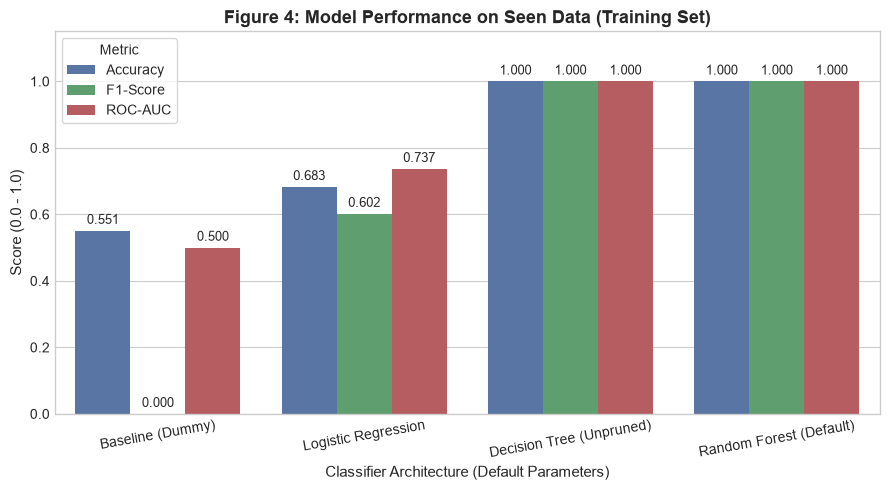

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style consistent with 01_eda.ipynb
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Reshape training evaluation results for grouped bar plotting
metrics_to_plot = ['Accuracy', 'F1-Score', 'ROC-AUC']
df_plot = df_seen.melt(
    id_vars='Model',
    value_vars=metrics_to_plot,
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=df_plot,
    x='Model',
    y='Score',
    hue='Metric',
    palette=['#4C72B0', '#55A868', '#C44E52']
)

plt.title('Figure 4: Model Performance on Seen Data (Training Set)', fontsize=13, weight='bold')
plt.xlabel('Classifier Architecture (Default Parameters)', fontsize=11)
plt.ylabel('Score (0.0 - 1.0)', fontsize=11)
plt.ylim(0, 1.15)
plt.xticks(rotation=10)
plt.legend(title='Metric', loc='upper left', frameon=True)

# Annotate exact values on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=9, padding=3)

plt.tight_layout()
os.makedirs('../report/figures', exist_ok=True)
plt.savefig('../report/figures/fig4_seen_data_comparison.png', dpi=300)
plt.show()